# 03 · Exploración de ventas · Objetivo 1 (clustering de platos)

**Objetivo:** entender cómo son los datos de ventas antes de agrupar los platos por rendimiento, y decidir **qué variables** usaremos para el clustering.

**Punto de partida:** el Parquet limpio del notebook 01 (`ventas_limpio.parquet`, una fila por plato, día, franja y ciudad). Aquí **no se limpia nada**: solo se explora, se comprueba que los datos son coherentes y se construye la tabla de **una fila por plato**, que es lo que agruparemos.

**Qué entrega este notebook:** `platos_features.parquet` (80 filas, una por plato) en la zona `clean` de HDFS, más las conclusiones para el notebook de clustering.

**Cómo ejecutarlo:** *Kernel → Restart & Run All*. Las celdas se pueden ejecutar en orden de arriba abajo sin tocar nada.

**Índice**
0. Configuración y funciones
1. Carga y validación
2. Variables categóricas
3. Variables numéricas por fila
4. Evolución temporal y contexto
5. Tabla por plato (una fila por plato)
6. Distribuciones, atípicos y correlaciones por plato
7. Selección de variables para el clustering
8. Conclusiones
9. Guardado

---
## 0. Configuración y funciones

Todo lo que se puede cambiar (rutas, umbrales, listas de columnas, colores) está **en una sola celda**. Las operaciones que se repiten (histogramas, atípicos, validaciones) son **funciones** con su documentación, para no copiar y pegar código.

In [1]:
from __future__ import annotations   # permite usar list[str] o float | None en versiones antiguas de Python

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# ---------- Rutas: HDFS por WebHDFS (las variables de entorno vienen del contenedor) ----------
HOST = os.environ.get("HDFS_WEBHDFS_URL", "http://namenode:9870").replace("http://", "")
OPT = {"user": os.environ.get("HDFS_USER", "root")}          # usuario con el que se accede a HDFS
CLEAN = f"webhdfs://{HOST}/datalake/clean"
RUTA_VENTAS = f"{CLEAN}/ventas_diarias_platos/ventas_limpio.parquet"      # entrada (notebook 01)
RUTA_PLATOS = f"{CLEAN}/ventas_diarias_platos/platos_features.parquet"    # salida (este notebook)

# ---------- Parámetros del análisis ----------
RANDOM_STATE = 42             # misma semilla en todo el notebook: los resultados se pueden repetir
UMBRAL_IQR = 1.5              # un valor es atípico si queda a más de 1,5 IQR de los cuartiles
N_PLATOS_ESPERADOS = 80       # el notebook 01 deja 80 platos
FORMATO_FECHA = "%d-%m-%Y"
TOLERANCIA_MARGEN = 0.011     # diferencia máxima (€) entre margen guardado y precio - coste (redondeo)
K_PROBADOS = range(2, 7)      # nº de grupos que probamos en la vista previa de clustering

COLS_CATEGORICAS = ["franja", "ciudad", "categoria"]
COLS_NUMERICAS = ["precio_unidad", "coste_unidad", "margen_unitario", "unidades_vendidas",
                  "clientes_dia", "popularidad"]
VARS_PLATO = ["popularidad", "precio_medio", "coste_medio", "margen_medio", "valoracion", "dificultad"]

# Qué mide el eje x de cada variable (con sus unidades), para que los gráficos se entiendan solos
ETIQUETAS = {
    "precio_unidad": "precio por unidad (€)",
    "coste_unidad": "coste por unidad (€)",
    "margen_unitario": "margen por unidad (€)",
    "unidades_vendidas": "unidades vendidas en la fila",
    "clientes_dia": "clientes del día",
    "popularidad": "popularidad (unidades vendidas / cliente)",
    "precio_medio": "precio medio (€)",
    "coste_medio": "coste medio (€)",
    "margen_medio": "margen medio (€)",
    "valoracion": "valoración (puntos)",
    "dificultad": "dificultad de elaboración (1 a 10)",
    "popularidad_media_diaria": "media de la popularidad diaria",
    "popularidad_mediana_diaria": "mediana de la popularidad diaria",
}

# ---------- Colores de Smart-Restaurant ----------
AZUL = "#1F3A44"          # azul petróleo
NARANJA = "#F28C38"
GRIS_AZULADO = "#5C808E"
MELOCOTON = "#FFE0C2"
CMAP_DIV = LinearSegmentedColormap.from_list("sr_div", [AZUL, "#FFFFFF", NARANJA])

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.edgecolor": GRIS_AZULADO, "axes.labelcolor": AZUL, "text.color": AZUL})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
def validar(condicion: bool, mensaje: str) -> None:
    """Comprueba algo que debe cumplirse. Si falla, detiene el notebook con un mensaje claro."""
    assert condicion, f"FALLO: {mensaje}"
    print(f"OK · {mensaje}")


def limites_iqr(serie: pd.Series, k: float = UMBRAL_IQR) -> tuple[float, float]:
    """Devuelve (límite inferior, límite superior) de la regla del rango intercuartílico."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def contar_atipicos(serie: pd.Series, k: float = UMBRAL_IQR) -> int:
    """Cuenta los valores fuera de los límites del IQR."""
    bajo, alto = limites_iqr(serie, k)
    return int(((serie < bajo) | (serie > alto)).sum())


def resumen_numerico(df: pd.DataFrame, columnas: list[str]) -> pd.DataFrame:
    """Estadísticos básicos + asimetría + nº y % de atípicos, una fila por columna."""
    resumen = df[columnas].describe().T
    resumen["asimetria"] = df[columnas].skew()
    resumen["atipicos"] = [contar_atipicos(df[c]) for c in columnas]
    resumen["% atipicos"] = resumen["atipicos"] / len(df) * 100
    return resumen


def histogramas(df: pd.DataFrame, columnas: list[str], n_columnas: int = 3, bins: int = 30,
                percentil_max: float | None = None, etiqueta_y: str = "nº de filas") -> None:
    """Un histograma por columna: eje x = valor de la variable, eje y = cuántas filas (o platos) caen en cada tramo.

    Con `percentil_max` se recorta la cola larga para poder ver el cuerpo de la distribución.
    """
    n_filas = int(np.ceil(len(columnas) / n_columnas))
    fig, axes = plt.subplots(n_filas, n_columnas, figsize=(4.3 * n_columnas, 3.1 * n_filas))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columnas):
        datos = df[col]
        if percentil_max is not None:
            datos = datos[datos <= datos.quantile(percentil_max)]
        sns.histplot(datos, bins=bins, color=AZUL, ax=ax)
        ax.set_title(col if percentil_max is None else f"{col} (hasta el percentil {percentil_max:.0%})")
        ax.set_xlabel(ETIQUETAS.get(col, col))
        ax.set_ylabel(etiqueta_y)
    for ax in axes[len(columnas):]:
        ax.set_visible(False)             # esconde los huecos si sobran ejes
    fig.tight_layout()
    plt.show()


def barras_conteo(df: pd.DataFrame, columnas: list[str]) -> None:
    """Un gráfico de barras con el nº de filas de cada categoría, para cada columna."""
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.3 * len(columnas), 3.1))
    for ax, col in zip(np.atleast_1d(axes), columnas):
        conteo = df[col].value_counts()
        sns.barplot(x=conteo.index.astype(str), y=conteo.values, color=AZUL, ax=ax)
        ax.set_title(f"Filas por {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("nº de filas")
    fig.tight_layout()
    plt.show()


def variacion_entre_grupos(df: pd.DataFrame, grupo: str, valor: str) -> float:
    """Diferencia relativa (%) entre el grupo con la media más alta y el más baja, sobre la media global."""
    medias = df.groupby(grupo)[valor].mean()
    return (medias.max() - medias.min()) / df[valor].mean() * 100


def construir_tabla_platos(df: pd.DataFrame) -> pd.DataFrame:
    """Resume las ventas en una fila por plato.

    La popularidad del plato se calcula como unidades totales / clientes totales (cociente de sumas),
    no como media de la popularidad diaria: así un día con 3 clientes no pesa como un día con 90.
    Se conservan también la media y la mediana diarias para poder compararlas (sección 5).
    """
    tabla = df.groupby("id_plato").agg(
        n_filas=("id_plato", "size"),
        unidades_totales=("unidades_vendidas", "sum"),
        clientes_totales=("clientes_dia", "sum"),
        unidades_medias=("unidades_vendidas", "mean"),
        popularidad_media_diaria=("popularidad", "mean"),
        popularidad_mediana_diaria=("popularidad", "median"),
        precio_medio=("precio_unidad", "mean"),
        coste_medio=("coste_unidad", "mean"),
        margen_medio=("margen_unitario", "mean"),
        valoracion=("valoracion", "first"),               # constante dentro de cada plato (se valida antes)
        dificultad=("dificultad_elaboracion", "first"),   # idem
    )
    tabla["popularidad"] = tabla["unidades_totales"] / tabla["clientes_totales"]
    return tabla.reset_index()


def silhouette_por_k(X: np.ndarray, ks=K_PROBADOS) -> pd.Series:
    """Silhouette de K-Means para cada nº de grupos (más cerca de 1 = grupos más separados)."""
    resultado = {}
    for k in ks:
        etiquetas = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
        resultado[k] = silhouette_score(X, etiquetas)
    return pd.Series(resultado)


def guardar_parquet(df: pd.DataFrame, ruta: str) -> None:
    """Guarda en Parquet, lo vuelve a leer y comprueba que es idéntico en forma y columnas."""
    df.to_parquet(ruta, storage_options=OPT, index=False)
    leido = pd.read_parquet(ruta, storage_options=OPT)
    validar(leido.shape == df.shape and list(leido.columns) == list(df.columns),
            f"guardado en {ruta.split('/datalake/')[-1]} · {leido.shape[0]} filas × {leido.shape[1]} columnas")

---
## 1. Carga y validación

Cargamos el Parquet limpio y pasamos `fecha` (que viene como texto) a fecha real. Antes de analizar nada comprobamos con `validar(...)` lo que **damos por supuesto**: si alguna cosa no se cumple, el notebook se para aquí y sabemos que el problema está en los datos de entrada, no en el análisis.

In [3]:
ventas = pd.read_parquet(RUTA_VENTAS, storage_options=OPT)
ventas["fecha"] = pd.to_datetime(ventas["fecha"], format=FORMATO_FECHA)   # falla si algún texto no es fecha

print(f"Filas: {len(ventas):,} | Columnas: {ventas.shape[1]}")
display(ventas.head())
display(ventas.dtypes.to_frame("tipo").T)

Filas: 103,790 | Columnas: 13


,id_plato,fecha,franja,ciudad,categoria,precio_unidad,coste_unidad,unidades_vendidas,clientes_dia,popularidad,margen_unitario,valoracion,dificultad_elaboracion
0,46,2024-07-18,cena,Sevilla,entrante,21.840,8.910,34,36,0.944,12.930,4.300,4
1,80,2024-06-07,comida,Sevilla,principal,7.680,2.620,4,73,0.055,5.060,4.800,9
2,51,2023-11-16,cena,Sevilla,entrante,21.920,9.900,11,50,0.220,12.020,4.400,4
3,9,2023-11-06,terraza,Valencia,principal,26.000,11.010,11,40,0.275,14.990,5.000,7
4,70,2024-06-26,cena,Madrid,principal,13.430,6.390,35,48,0.729,7.040,4.600,6


,id_plato,fecha,franja,ciudad,categoria,precio_unidad,coste_unidad,unidades_vendidas,clientes_dia,popularidad,margen_unitario,valoracion,dificultad_elaboracion
tipo,int64,datetime64[ns],object,object,object,float64,float64,int64,int64,float64,float64,float64,int64


In [4]:
# Lo que damos por supuesto tras el notebook 01
validar(int(ventas.isna().sum().sum()) == 0, "no hay celdas vacías")
validar(int(ventas.duplicated().sum()) == 0, "no hay filas duplicadas")
validar(ventas["id_plato"].nunique() == N_PLATOS_ESPERADOS, f"hay {N_PLATOS_ESPERADOS} platos distintos")
validar(pd.api.types.is_integer_dtype(ventas["id_plato"]), "id_plato es un número entero (sin prefijo PL-)")
validar((ventas["clientes_dia"] > 0).all(), "clientes_dia es siempre mayor que 0 (se puede dividir por él)")
validar((ventas["unidades_vendidas"] >= 0).all(), "unidades_vendidas nunca es negativa")
validar(((ventas["precio_unidad"] - ventas["coste_unidad"] - ventas["margen_unitario"]).abs()
         <= TOLERANCIA_MARGEN).all(), "margen_unitario = precio_unidad - coste_unidad en todas las filas")

# valoracion y dificultad son atributos del plato: un solo valor por plato
por_plato = ventas.groupby("id_plato")[["valoracion", "dificultad_elaboracion"]].nunique()
validar(int(por_plato.max().max()) == 1, "cada plato tiene una única valoración y una única dificultad")

print(f"\nRango de fechas: {ventas['fecha'].min():%d-%m-%Y} → {ventas['fecha'].max():%d-%m-%Y}")

OK · no hay celdas vacías
OK · no hay filas duplicadas
OK · hay 80 platos distintos
OK · id_plato es un número entero (sin prefijo PL-)
OK · clientes_dia es siempre mayor que 0 (se puede dividir por él)
OK · unidades_vendidas nunca es negativa
OK · margen_unitario = precio_unidad - coste_unidad en todas las filas
OK · cada plato tiene una única valoración y una única dificultad

Rango de fechas: 01-01-2023 → 31-12-2025


---
## 2. Variables categóricas

`franja`, `ciudad` y `categoria`. Miramos si están equilibradas y si `categoria` es un atributo fijo de cada plato.

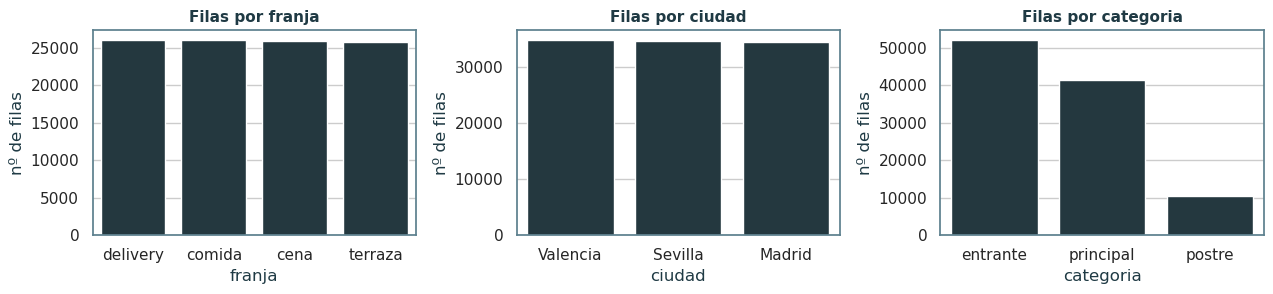

,nº de platos
categorías distintas en un plato,
3,80


In [5]:
barras_conteo(ventas, COLS_CATEGORICAS)

# ¿Cuántas categorías distintas aparecen dentro de un mismo plato?
cats_por_plato = ventas.groupby("id_plato")["categoria"].nunique()
display(cats_por_plato.value_counts().sort_index().rename_axis("categorías distintas en un plato")
        .to_frame("nº de platos"))

---
## 3. Variables numéricas por fila

Cada fila es un plato en un día, franja y ciudad. Miramos la forma de cada variable, los valores atípicos y si los datos son coherentes entre sí.

,count,mean,std,min,25%,50%,75%,max,asimetria,atipicos,% atipicos
precio_unidad,"103,790.000",15.989,6.907,4.000,10.120,15.880,22.000,28.000,0.012,0,0.000
coste_unidad,"103,790.000",6.097,3.325,0.740,3.430,5.500,8.300,16.210,0.638,137,0.132
margen_unitario,"103,790.000",9.892,4.744,-3.400,5.970,9.540,13.240,22.920,0.354,0,0.000
unidades_vendidas,"103,790.000",24.197,15.763,0.000,12.000,24.000,35.000,105.000,0.348,366,0.353
clientes_dia,"103,790.000",48.128,21.061,1.000,32.000,48.000,63.000,133.000,0.095,80,0.077
popularidad,"103,790.000",0.764,1.626,0.000,0.241,0.491,0.844,71.000,15.140,7023,6.767


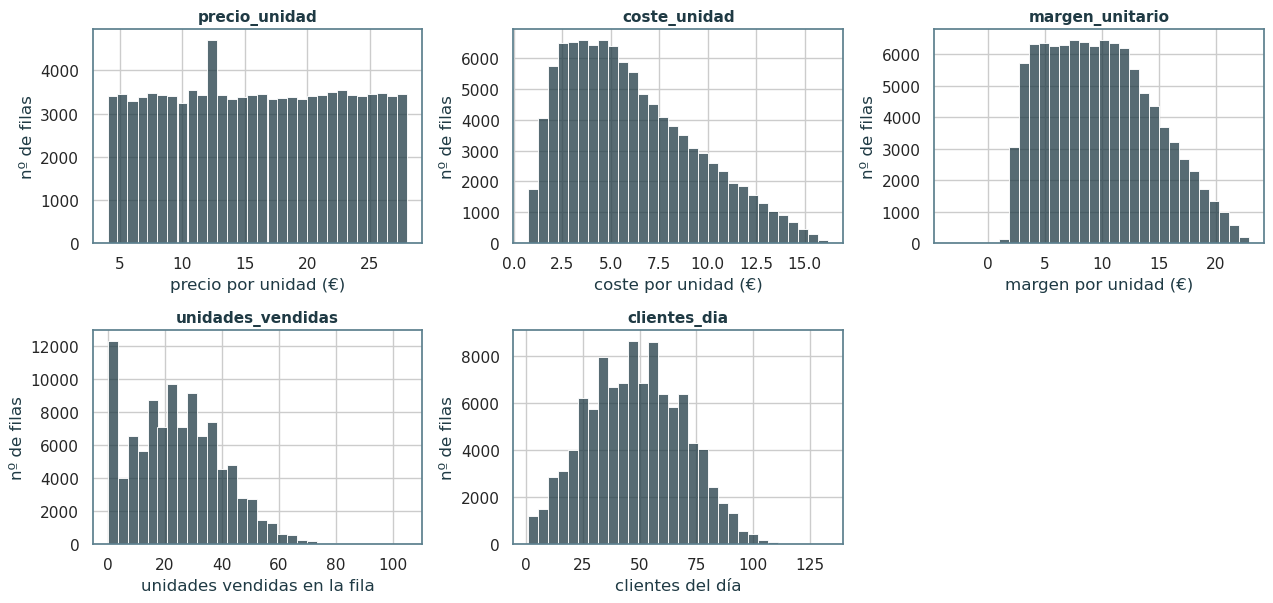

In [6]:
display(resumen_numerico(ventas, COLS_NUMERICAS))
histogramas(ventas, COLS_NUMERICAS[:5], bins=30)

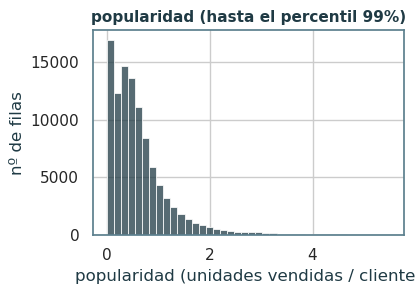

Percentiles de popularidad (unidades vendidas / clientes del día):


,0.500,0.900,0.990,0.999,1.000
popularidad,0.491,1.412,5.500,23.606,71.000


In [7]:
# La popularidad tiene una cola muy larga: la dibujamos recortada al percentil 99 para ver el cuerpo
histogramas(ventas, ["popularidad"], n_columnas=1, bins=40, percentil_max=0.99)

print("Percentiles de popularidad (unidades vendidas / clientes del día):")
display(ventas["popularidad"].quantile([0.5, 0.9, 0.99, 0.999, 1]).to_frame("popularidad").T)

La media de `popularidad` queda por encima de la mediana y el máximo es enorme. Como es un **cociente**, el problema debe de estar en el denominador: los días con muy pocos clientes. Lo comprobamos.

In [8]:
# Popularidad según los clientes que hubo ese día
tramos = pd.cut(ventas["clientes_dia"], bins=[0, 5, 10, 20, 50, np.inf],
                labels=["1-5", "6-10", "11-20", "21-50", "más de 50"])
por_tramo = ventas.groupby(tramos, observed=True)["popularidad"].agg(
    filas="size", media="mean", mediana="median")
display(por_tramo)

# ¿Las unidades vendidas dependen de los clientes?
corr_uc = ventas["unidades_vendidas"].corr(ventas["clientes_dia"])
print(f"Correlación unidades_vendidas ~ clientes_dia: {corr_uc:.2f}")
print(f"Filas con unidades > clientes (popularidad > 1): {(ventas['unidades_vendidas'] > ventas['clientes_dia']).mean():.1%}")
print(f"Filas con menos de 6 clientes: {(ventas['clientes_dia'] <= 5).mean():.1%}")

,filas,media,mediana
clientes_dia,,,
1-5,1204,10.015,7.400
6-10,1978,3.053,2.900
11-20,7362,1.560,1.467
21-50,45920,0.701,0.647
más de 50,47326,0.371,0.352


Correlación unidades_vendidas ~ clientes_dia: -0.00
Filas con unidades > clientes (popularidad > 1): 18.3%
Filas con menos de 6 clientes: 1.2%


In [9]:
# Coherencia entre variables
margen_negativo = ventas[ventas["margen_unitario"] < 0]
print(f"Filas con margen negativo (coste > precio): {len(margen_negativo)} ({len(margen_negativo)/len(ventas):.2%})")
display(margen_negativo[["id_plato", "precio_unidad", "coste_unidad", "margen_unitario"]].head())
print("Platos afectados:", margen_negativo["id_plato"].nunique())

Filas con margen negativo (coste > precio): 54 (0.05%)


,id_plato,precio_unidad,coste_unidad,margen_unitario
112,38,12.500,12.660,-0.160
1200,77,12.500,14.940,-2.440
1300,39,12.500,14.170,-1.670
2433,47,12.500,14.170,-1.670
3927,66,12.500,14.420,-1.920


Platos afectados: 42


---
## 4. Evolución temporal y contexto

¿Se vende más en algún mes, día de la semana, franja o ciudad? Si no hay diferencias, esas columnas no ayudarán a distinguir platos.

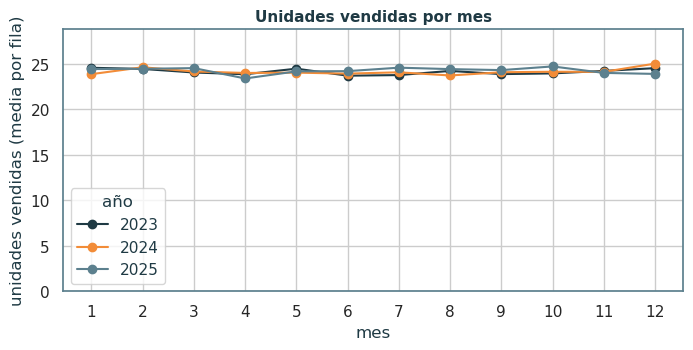

,% de diferencia (mejor vs peor grupo)
anio,0.507
mes,3.147
dia_semana,1.659
franja,0.585
ciudad,0.601
categoria,0.573


In [10]:
ventas_t = ventas.assign(anio=ventas["fecha"].dt.year, mes=ventas["fecha"].dt.month,
                         dia_semana=ventas["fecha"].dt.dayofweek)

# Unidades medias por mes, una línea por año
mensual = ventas_t.groupby(["anio", "mes"])["unidades_vendidas"].mean().unstack("anio")
fig, ax = plt.subplots(figsize=(8, 3.4))
for anio, color in zip(mensual.columns, [AZUL, NARANJA, GRIS_AZULADO]):
    ax.plot(mensual.index, mensual[anio], marker="o", color=color, label=str(anio))
ax.set_xticks(range(1, 13))
ax.set_ylim(0, mensual.max().max() * 1.15)      # eje desde 0: así no se exagera una diferencia pequeña
ax.set_xlabel("mes")
ax.set_ylabel("unidades vendidas (media por fila)")
ax.set_title("Unidades vendidas por mes")
ax.legend(title="año")
plt.show()

# Cuánto cambia la media entre el mejor y el peor grupo, en % de la media global
variacion = pd.DataFrame({
    "% de diferencia (mejor vs peor grupo)": {
        grupo: variacion_entre_grupos(ventas_t, grupo, "unidades_vendidas")
        for grupo in ["anio", "mes", "dia_semana", "franja", "ciudad", "categoria"]}})
display(variacion)

---
## 5. Tabla por plato (una fila por plato)

El clustering agrupa **platos**, no filas, así que resumimos cada plato en una fila. La duda es cómo resumir la popularidad: la media de la popularidad diaria arrastra los días con pocos clientes (sección 3). Comparamos tres formas de calcularla:

- **Media diaria** de unidades/clientes.
- **Mediana diaria** de unidades/clientes.
- **Cociente de sumas:** unidades totales / clientes totales.

In [11]:
platos = construir_tabla_platos(ventas)

validar(len(platos) == N_PLATOS_ESPERADOS, f"la tabla tiene {N_PLATOS_ESPERADOS} filas, una por plato")
validar(int(platos.isna().sum().sum()) == 0, "la tabla por plato no tiene vacíos")
validar(platos["n_filas"].min() > 1000, f"todos los platos tienen más de 1.000 filas (mínimo: {platos['n_filas'].min()})")

definiciones = ["popularidad_media_diaria", "popularidad_mediana_diaria", "popularidad"]
display(platos[definiciones].describe().T)
print("Correlación entre las tres formas de calcular la popularidad (80 platos):")
display(platos[definiciones].corr())

OK · la tabla tiene 80 filas, una por plato
OK · la tabla por plato no tiene vacíos
OK · todos los platos tienen más de 1.000 filas (mínimo: 1218)


,count,mean,std,min,25%,50%,75%,max
popularidad_media_diaria,80.000,0.764,0.049,0.662,0.728,0.762,0.798,0.904
popularidad_mediana_diaria,80.000,0.491,0.015,0.456,0.480,0.491,0.500,0.523
popularidad,80.000,0.503,0.011,0.474,0.496,0.504,0.511,0.523


Correlación entre las tres formas de calcular la popularidad (80 platos):


,popularidad_media_diaria,popularidad_mediana_diaria,popularidad
popularidad_media_diaria,1.000,0.287,0.432
popularidad_mediana_diaria,0.287,1.000,0.824
popularidad,0.432,0.824,1.000


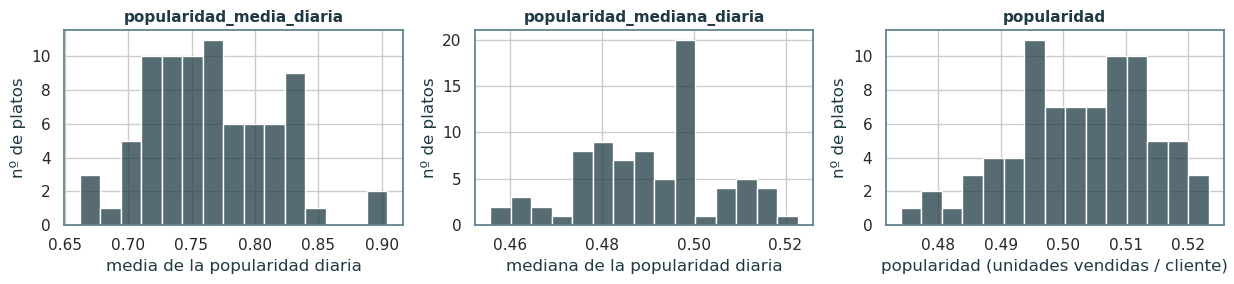

In [12]:
# Reparto de cada definición: ¿cuánto se diferencian unos platos de otros?
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3))
for ax, col in zip(axes, definiciones):
    sns.histplot(platos[col], bins=15, color=AZUL, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(ETIQUETAS[col])
    ax.set_ylabel("nº de platos")
fig.tight_layout()
plt.show()

---
## 6. Distribuciones, atípicos y correlaciones por plato

A partir de aquí trabajamos con los 80 platos. Usamos la popularidad calculada como **cociente de sumas** (columna `popularidad`).

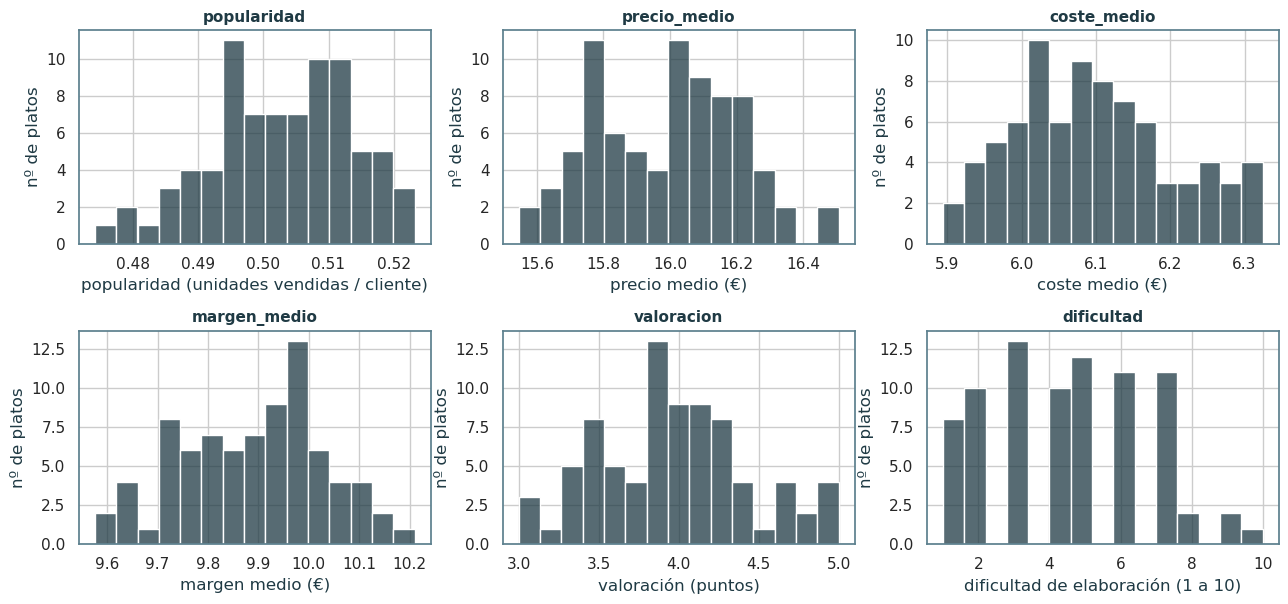

,mean,std,min,max,variacion (%),asimetria,atipicos
popularidad,0.503,0.011,0.474,0.523,2.205,-0.368,0
precio_medio,15.990,0.215,15.546,16.507,1.344,0.048,0
coste_medio,6.098,0.106,5.894,6.324,1.734,0.279,0
margen_medio,9.892,0.144,9.576,10.210,1.454,-0.148,0
valoracion,3.956,0.472,3.000,5.000,11.929,0.243,0
dificultad,4.425,2.203,1.000,10.000,49.795,0.227,0


In [13]:
histogramas(platos, VARS_PLATO, n_columnas=3, bins=15, etiqueta_y="nº de platos")

resumen = resumen_numerico(platos, VARS_PLATO)
# Coeficiente de variación: cuánto varía cada variable entre platos, relativo a su media
resumen["variacion (%)"] = platos[VARS_PLATO].std() / platos[VARS_PLATO].mean() * 100
display(resumen[["mean", "std", "min", "max", "variacion (%)", "asimetria", "atipicos"]])

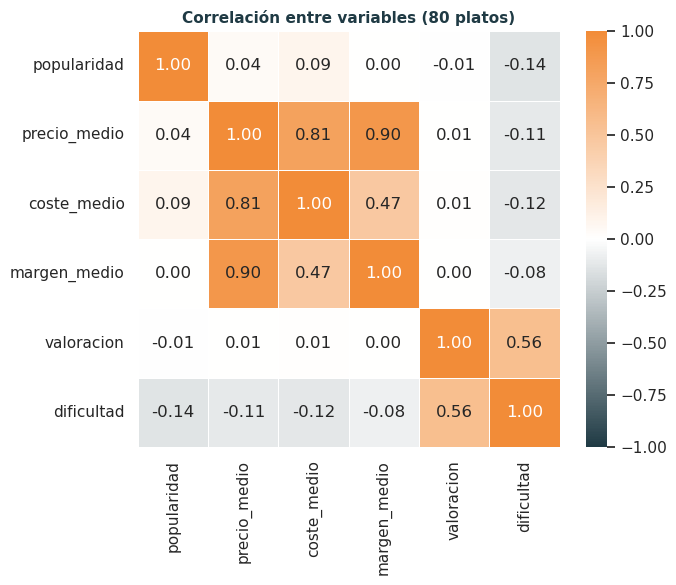

,variable 1,variable 2,r
6,precio_medio,margen_medio,0.901
5,precio_medio,coste_medio,0.807


In [14]:
# Correlaciones entre las variables de los platos
corr = platos[VARS_PLATO].corr()
fig, ax = plt.subplots(figsize=(6.8, 5.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Correlación entre variables (80 platos)")
plt.show()

# Pares muy correlacionados (|r| > 0,7), sin repetir ni contar cada variable consigo misma
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "variable 1", "level_1": "variable 2"}))
display(pares[pares["r"].abs() > 0.7].sort_values("r", ascending=False))

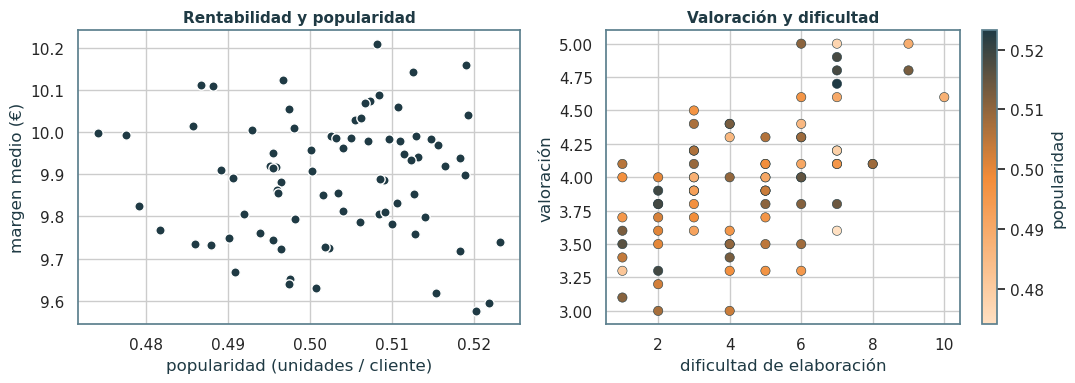

In [15]:
# Relaciones que más interesan para el negocio: rentabilidad frente a popularidad, y valoración frente a dificultad
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(platos["popularidad"], platos["margen_medio"], color=AZUL, s=45, edgecolor="white")
axes[0].set_xlabel("popularidad (unidades / cliente)")
axes[0].set_ylabel("margen medio (€)")
axes[0].set_title("Rentabilidad y popularidad")
sc = axes[1].scatter(platos["dificultad"], platos["valoracion"], c=platos["popularidad"],
                     cmap=LinearSegmentedColormap.from_list("sr_seq", [MELOCOTON, NARANJA, AZUL]),
                     s=45, edgecolor=AZUL, linewidth=0.4)
fig.colorbar(sc, ax=axes[1], label="popularidad")
axes[1].set_xlabel("dificultad de elaboración")
axes[1].set_ylabel("valoración")
axes[1].set_title("Valoración y dificultad")
fig.tight_layout()
plt.show()

---
## 7. Selección de variables para el clustering

Comparamos tres conjuntos de variables. Para cada uno vemos cuánta información resume el PCA y qué grupos separa K-Means (**vista previa, no es el modelo final**; el modelo irá en el notebook 04). El silhouette va de −1 a 1: por encima de ~0,5 hay grupos claros, entre ~0,25 y ~0,5 la estructura es débil y por debajo de ~0,25 no hay estructura.

- **A · Las del enunciado:** popularidad, precio, coste y margen.
- **B · Sin redundancias:** popularidad y margen, más valoración y dificultad (precio y coste ya están dentro del margen).
- **C · Solo rendimiento:** popularidad y margen.

In [16]:
CONJUNTOS = {
    "A · popularidad, precio, coste, margen": ["popularidad", "precio_medio", "coste_medio", "margen_medio"],
    "B · popularidad, margen, valoración, dificultad": ["popularidad", "margen_medio", "valoracion", "dificultad"],
    "C · popularidad, margen": ["popularidad", "margen_medio"],
}

silhouettes, varianza_pc12 = {}, {}
for nombre, columnas in CONJUNTOS.items():
    X = StandardScaler().fit_transform(platos[columnas])        # misma escala: media 0 y desviación 1
    silhouettes[nombre] = silhouette_por_k(X)
    pca = PCA(random_state=RANDOM_STATE).fit(X)
    varianza_pc12[nombre] = pca.explained_variance_ratio_[:2].sum() * 100

print("Silhouette de K-Means según el nº de grupos (k):")
display(pd.DataFrame(silhouettes).rename_axis("k"))
print("Varianza que explican las dos primeras componentes del PCA (%):")
display(pd.Series(varianza_pc12, name="% varianza").to_frame().round(1))

Silhouette de K-Means según el nº de grupos (k):


,"A · popularidad, precio, coste, margen","B · popularidad, margen, valoración, dificultad","C · popularidad, margen"
k,,,
2,0.371,0.233,0.341
3,0.274,0.202,0.363
4,0.273,0.216,0.367
5,0.268,0.223,0.367
6,0.289,0.217,0.385


Varianza que explican las dos primeras componentes del PCA (%):


,% varianza
"A · popularidad, precio, coste, margen",86.900
"B · popularidad, margen, valoración, dificultad",64.600
"C · popularidad, margen",100.000


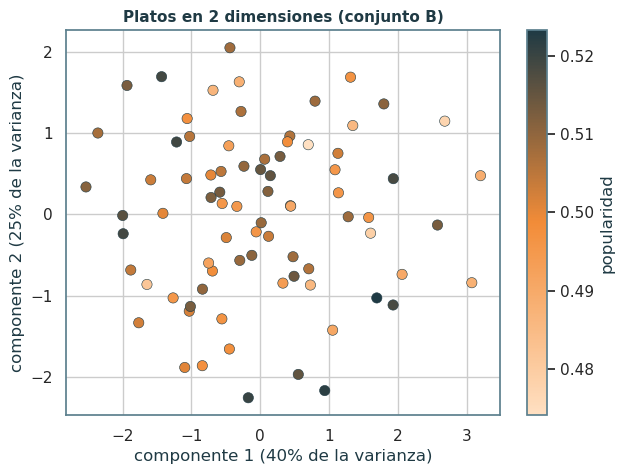

Peso de cada variable en las componentes:


,comp. 1,comp. 2
popularidad,-0.172,-0.083
margen_medio,-0.092,0.990
valoracion,0.681,0.114
dificultad,0.706,-0.001


In [17]:
# Vista en 2 dimensiones del conjunto B, coloreada por la popularidad
columnas_b = CONJUNTOS["B · popularidad, margen, valoración, dificultad"]
X_b = StandardScaler().fit_transform(platos[columnas_b])
pca_b = PCA(n_components=2, random_state=RANDOM_STATE)
proyeccion = pca_b.fit_transform(X_b)

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(proyeccion[:, 0], proyeccion[:, 1], c=platos["popularidad"],
                cmap=LinearSegmentedColormap.from_list("sr_seq", [MELOCOTON, NARANJA, AZUL]),
                s=55, edgecolor=AZUL, linewidth=0.4)
fig.colorbar(sc, ax=ax, label="popularidad")
ax.set_xlabel(f"componente 1 ({pca_b.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"componente 2 ({pca_b.explained_variance_ratio_[1]:.0%} de la varianza)")
ax.set_title("Platos en 2 dimensiones (conjunto B)")
plt.show()

print("Peso de cada variable en las componentes:")
display(pd.DataFrame(pca_b.components_.T, index=columnas_b, columns=["comp. 1", "comp. 2"]))

---
## 8. Conclusiones

**Sobre los datos**
- Los datos de entrada son coherentes: sin vacíos ni duplicados, 80 platos con entre 1.218 y 1.375 filas cada uno (2023-2025) y `margen = precio − coste` en todas las filas.
- `categoria` **no describe al plato**: los 80 platos aparecen en las tres categorías. Por eso no la usamos para agrupar.
- `franja`, `ciudad`, año, día de la semana y categoría están equilibradas y casi no cambian las ventas (menos de un 1,7 % de diferencia entre grupos; el mes llega al 3,1 %). No hay estacionalidad ni patrones por contexto que expliquen diferencias entre platos.
- Hay 54 filas con margen negativo (0,05 %, repartidas en 42 platos) y un pico de precio en 12,50 €. Son pocas, no cambian el resultado por plato y no se tocan.

**Sobre la popularidad (la variable clave)**
- Por fila, `popularidad` tiene una cola muy larga (asimetría 15 y 6,8 % de atípicos). La causa: las **unidades vendidas no dependen de los clientes** (correlación ≈ 0), así que los días con pocos clientes disparan el cociente (con 1-5 clientes la media es 10, con más de 50 es 0,37).
- Por eso calculamos la popularidad del plato como **unidades totales / clientes totales**. La media de la popularidad diaria apenas se parece a ella (r = 0,43) y arrastra los días con pocos clientes; la mediana sí (r = 0,82).

**Sobre los platos**
- Los platos se parecen mucho entre sí: popularidad, precio, coste y margen varían solo entre un 1,3 % y un 2,2 % entre platos. Solo `valoracion` (12 %) y `dificultad` (50 %) varían de verdad. No hay platos atípicos.
- Hay redundancia: `precio_medio` va con `margen_medio` (r = 0,90) y con `coste_medio` (r = 0,81). `valoracion` y `dificultad` van juntas (r = 0,56). La popularidad no se relaciona con el margen (r = 0,00).

**Sobre el clustering**
- No se ven grupos naturales: el silhouette queda entre 0,20 y 0,39 (estructura débil o inexistente) y el PCA muestra una nube continua de platos. Los grupos que salgan serán **tramos de un espectro** (por ejemplo, más o menos populares y rentables), no grupos separados. Esto hay que decirlo así en el informe.
- Si metemos `valoracion` y `dificultad` (conjunto B), mandan sobre el resto: pesan casi todo en la primera componente y el silhouette baja a 0,20-0,23. Como el objetivo 1 es agrupar por **rendimiento**, esas dos variables no deberían definir los grupos.
- Los datos son sintéticos y las diferencias entre platos son pequeñas por cómo se generaron; conviene mencionarlo al presentar los resultados.

**Decisión para el notebook 04**
- Agrupar con **`popularidad` y `margen_medio`** (conjunto C), estandarizadas, con K-Means y clustering jerárquico para compararlos. Probar varios *k* y quedarnos con el que se pueda **explicar** mejor, no solo con el silhouette más alto.
- Usar `valoracion`, `dificultad`, `precio_medio` y `coste_medio` **después**, para describir y poner nombre a cada grupo.

---
## 9. Guardado

Guardamos la tabla por plato **sin las columnas auxiliares** (totales y definiciones alternativas de popularidad), solo con lo que usará el clustering.

In [18]:
COLUMNAS_SALIDA = ["id_plato", "n_filas", "unidades_medias", "popularidad", "precio_medio",
                   "coste_medio", "margen_medio", "valoracion", "dificultad"]
guardar_parquet(platos[COLUMNAS_SALIDA], RUTA_PLATOS)
display(platos[COLUMNAS_SALIDA].head())

OK · guardado en clean/ventas_diarias_platos/platos_features.parquet · 80 filas × 9 columnas


,id_plato,n_filas,unidades_medias,popularidad,precio_medio,coste_medio,margen_medio,valoracion,dificultad
0,1,1311,24.542,0.510,16.151,6.168,9.983,4.000,4
1,2,1264,24.619,0.518,15.749,6.032,9.718,4.800,7
2,3,1285,25.088,0.518,16.028,6.089,9.939,4.900,7
3,4,1331,24.592,0.502,15.834,5.983,9.851,3.900,3
4,5,1294,25.143,0.522,15.685,6.091,9.594,4.100,7
